In [1]:
import numpy as np
import pandas as pd
from numpy import linalg
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("elipsi_gamocda.xlsx", header=None)

In [3]:
df = df.transpose()
df.columns = ["x", "y"]

In [4]:
x = df["x"]
y = df["y"]

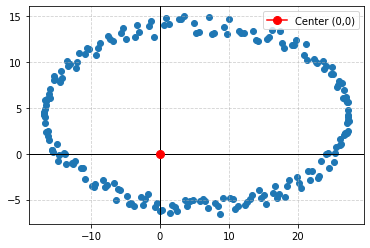

In [5]:
plt.scatter(x,y)
plt.axhline(0, color="black", linewidth=1, linestyle="-")
plt.axvline(0, color="black", linewidth=1, linestyle="-") 

# Mark the center point (0, 0)
plt.plot(0, 0, marker="o", markersize=8, color="red", label="Center (0,0)")

# Add grid and legend
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()


In [18]:
A = np.array([[2*sum(x**2*y**2),sum(y**3*x),2*sum(x**2*y),2*sum(y**2*x),sum(x*y)],
              [2*sum(x*y**3),sum(y**4),2*sum(x*y**2),2*sum(y**3),sum(y**2)],
              [2*sum(x**2*y),sum(y**2*x),2*sum(x**2),2*sum(y*x),sum(x)],
              [2*sum(x*y**2),sum(y**3),2*sum(x*y),2*sum(y**2),sum(y)],
              [2*sum(x*y),sum(y**2),2*sum(x),2*sum(y),len(x)]])
b = [-sum(x**3*y),-sum(x**2*y**2),-sum(x**3),-sum(x**2*y),-sum(x**2)]

In [19]:
coeff = linalg.solve(A,b)
coeff

array([ 1.55672813e-02,  4.70511398e+00, -5.32733515e+00, -1.98219709e+01,
       -3.62739655e+02])

In [20]:
a11 = 1
a12 = coeff[0]
a22 = coeff[1]
a13 = coeff[2]
a23 = coeff[3]
a33 = coeff[4]

In [21]:
#a11*x_pred**2 + 2*a12*x_pred*y_pred + a22*y_pred**2 + 2*a13*x_pred + 2*a23*y_pred + a33

In [22]:
D = linalg.det([[a11,a12],[a12,a22]])
I = a11+a22
A = linalg.det([[a11,a12,a13],[a12,a22,a23],[a13,a23,a33]])

x0 = -1*linalg.det([[a13,a12],[a23,a22]])/D
y0 = -1*linalg.det([[a11,a13],[a12,a23]])/D

In [23]:
disk1 = np.sqrt(I**2 - 4*D)
lambda1 = (I+disk1)/2
lambda2 = (I-disk1)/2

In [24]:
b = np.sqrt(-1*A/(lambda1*D))
a = np.sqrt(-1*A/(lambda2*D))

In [25]:
a

21.770742802579935

In [26]:
b

10.036237991093731

In [27]:
t = np.linspace(-10,10,1000)

In [ ]:
xx = a*np.cos(t) + x0
yy = b*np.sin(t) + y0

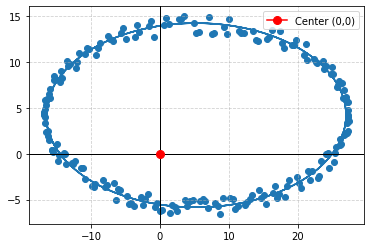

In [29]:
plt.plot(xx,yy)
plt.scatter(x,y)
plt.axhline(0, color="black", linewidth=1, linestyle="-")
plt.axvline(0, color="black", linewidth=1, linestyle="-") 

# Mark the center point (0, 0)
plt.plot(0, 0, marker="o", markersize=8, color="red", label="Center (0,0)")

# Add grid and legend
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()
